# Metamodel case generation

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from the case JSON → `simulations`.

In [1]:
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/templates-metamodel
cases     : /hyglowdata/NewSouthWales/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/GRID/NewSouthWales_mesh.nc
samples   : 500 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df

,goal,tp,dir,spr,wl
0,1,16.218551,325.501796,18.939314,0.744411
1,1,11.020150,325.293736,13.775162,-1.491274
2,1,8.389115,358.907874,13.077691,0.211695
3,1,6.687470,53.573091,42.685319,1.908372
4,1,9.392906,273.822630,21.310096,1.181901
...,...,...,...,...,...
12995,26,3.830798,283.873978,6.058686,0.949339
12996,26,7.198518,328.212030,26.999642,0.872916
12997,26,14.304880,165.029946,8.893153,-1.379262
12998,26,7.278644,338.046057,38.968768,-0.299015


In [4]:
import numpy as np

# Add a new column called save_map with 5% True
cases_df["save_map"] = np.random.choice(
    [True, False], size=len(cases_df), p=[0.05, 0.95]
)
cases_df.head(20)

,goal,tp,dir,spr,wl,save_map
0,1,16.218551,325.501796,18.939314,0.744411,False
1,1,11.020150,325.293736,13.775162,-1.491274,False
2,1,8.389115,358.907874,13.077691,0.211695,False
3,1,6.687470,53.573091,42.685319,1.908372,False
4,1,9.392906,273.822630,21.310096,1.181901,False
5,1,15.411486,238.676620,38.181303,-0.431846,False
6,1,13.883457,246.401092,21.632372,-0.874215,False
7,1,3.159895,19.613233,27.794586,-0.784927,False
8,1,13.402307,15.738259,10.274056,1.080662,False
9,1,5.444495,7.927421,10.375578,-0.776499,False


In [5]:
cases_df.groupby(["goal", "save_map"])[["tp"]].count()

tp
goal save_map     
1    False     478
     True       22
2    False     476
     True       24
3    False     485
     True       15
4    False     468
     True       32
5    False     479
     True       21
6    False     469
     True       31
7    False     480
     True       20
8    False     465
     True       35
9    False     480
     True       20
10   False     476
     True       24
11   False     478
     True       22
12   False     479
     True       21
13   False     472
     True       28
14   False     471
     True       29
15   False     467
     True       33
16   False     483
     True       17
17   False     478
     True       22
18   False     474
     True       26
19   False     479
     True       21
20   False     475
     True       25
21   False     482
     True       18
22   False     481
     True       19
23   False     471
     True       29
24   False     481
     True       19
25   False     480
     True       20
26   False     478
     True       22

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-08-04 13:45:35,283 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-08-04 13:45:35,283 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-08-04 13:45:35,284 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-08-04 13:45:35,285 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-08-04 13:45:35,285 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters
2026-08-04 13:45:35,286 - SnapWaveMetaModelWrapper - WARNING - Parameter save_map is not in the default_parameters


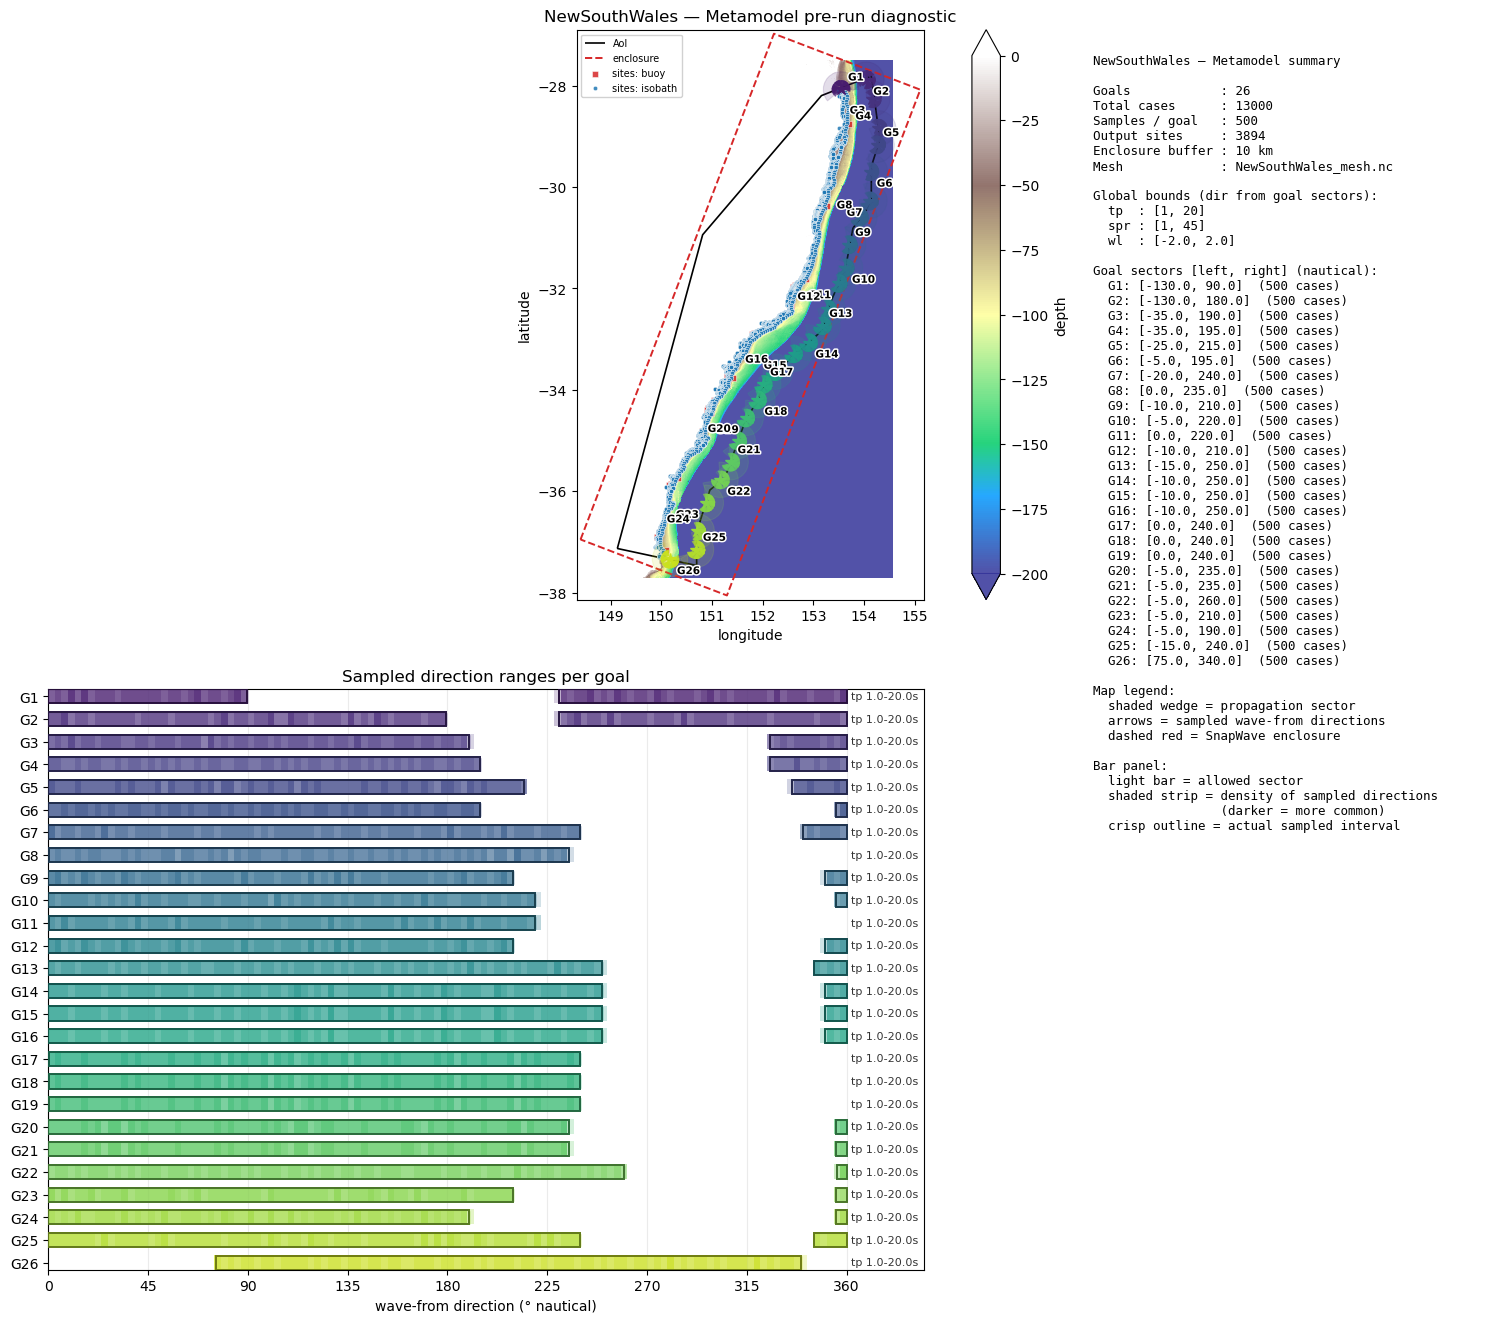

In [7]:
fig = wrapper.plot_configuration()
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [9]:
# cases_df.to_csv(resolve(cases_dir) / "cases.csv", index=False)
# wrapper.output_sites_df.to_csv(resolve(cases_dir) / "output_sites.csv", index=False)

In [10]:
# wrapper.cases_dir_to_txt()

In [11]:
# wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [15]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    13000
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map (or overview fallback)
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

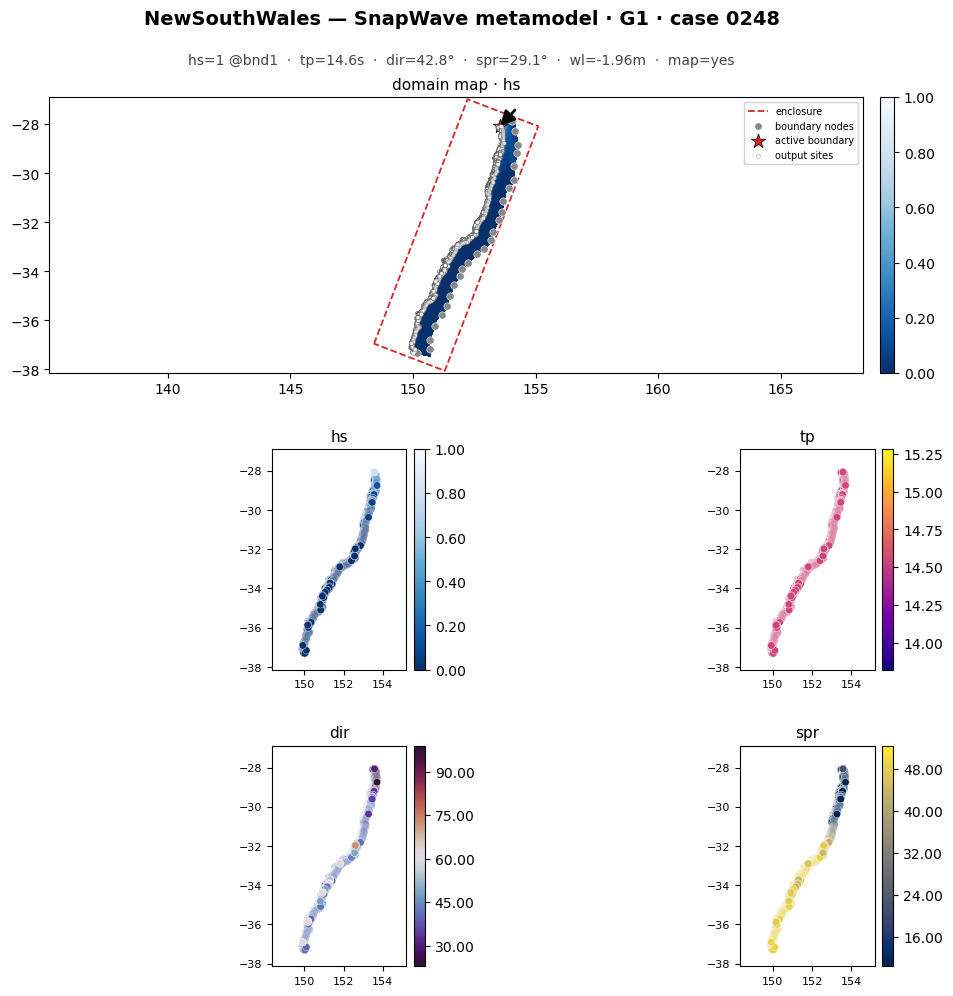

In [32]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(goal=1, case_num=248, style=style);

In [16]:
wrapper.postprocess_cases()

2026-08-04 14:03:23,896 - SnapWaveMetaModelWrapper - ERROR - Output not postprocessed for case 10156. Error: conflicting sizes for dimension 'case_num': length 1 on 'case_num' and length 0 on {'stations': 'station_name', 'case_num': 'point_zs'}.
2026-08-04 14:03:23,974 - SnapWaveMetaModelWrapper - ERROR - Output not postprocessed for case 10159. Error: conflicting sizes for dimension 'case_num': length 1 on 'case_num' and length 0 on {'stations': 'station_name', 'case_num': 'point_zs'}.


'Done'